###  This notebook calculates 0-D RE evolution during a Disruption

 Loading Modules

In [266]:
import sys
RE_path = './' # Path to RE.py -> This file contains required functions for calculating RE-relevant quantities
sys.path.insert(1, RE_path)

In [267]:
# Import other modules
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *
from scipy.integrate import solve_ivp
importlib.reload(RE)

<module 'RE' from '/Users/rishabhdatta/MIT Dropbox/Rishabh Datta/Rishabh_EP_Group/Code/RE_Solver/RE.py'>

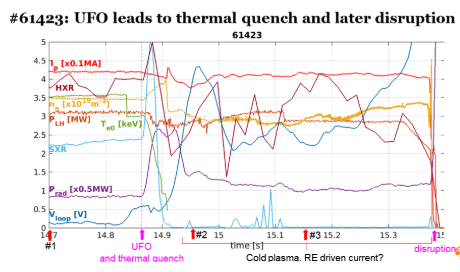

## Instantiate solver and define settings

In [268]:
solver = RE.solver0D()
solver.display() # Show default values


 Constants:
Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.000
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 5e+03
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001
Init. Vloop V0 [V] = 0
Final Vloop Vf [V] = 0

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 1


In [269]:
# Change solver settings

# Constants 
solver.R0 = 2.535 # Major Radius, [m]
solver.a = 0.5240  # Minor Radius, [m]
solver.ni = 2.5e19 # 2.50e19 (volume average), 4.09e+19 (core value) # ion density in plasma fuel, per m**3
solver.L = 2.04e-06        # plasma internal inductance [H] calculated as L = 2*W / Ip², 
solver.k = 1.328       # elongation
solver.n_imp = 1e-10

# Initial Conditions
solver.I0 = 0.421e6        # [A], Initial Plasma Current
solver.T0 = 3.55e03   # [eV], initial temperature
solver.Tf = 300       # [eV], post-TQ final temperature
solver.t0 = 50e-3     # [s] TQ duration
solver.Ir0 = 0.15e6   # [A], #  Initial RE current estimated to be equal to the LH-driven current fraction before TQ in the assumption that all LH-generated fast electrons become RE. This estimate must be considered as an upper limit.

# RE Sources
solver.iCompton = 0 # Turn on activated sources
solver.iTritium = 0
solver.iAvalanche = 1
solver.iDreicer = 1

solver.display()


 Constants:
Major radius R0 [m] = 2.535
Minor radius a [m] = 0.524
Elongation k [-] = 1.328
ni [per cubic m] = 2.5e+19
Inductance L [Henry] = 2.04e-06
Btor [Tesla] = 12.2

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 4.21e+05
Init. RE Current Ir0 [A] = 1.5e+05
Init. Temp. T0 [eV] = 3.55e+03
Final Temp. Tf [eV] = 300
Temp. decay time t0 [s] = 0.05
Init. Vloop V0 [V] = 0
Final Vloop Vf [V] = 0

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-10
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 1


## Solve

In [270]:
# solve
solver.tmax = 3000e-3 # end time [s]
solver.idiag = True # calculate detailed output
t, Ip, Ir, Wk = solver.solve()

Here, we will plot  𝐼𝑝 and  𝐼_𝑅𝐸 as a function of time

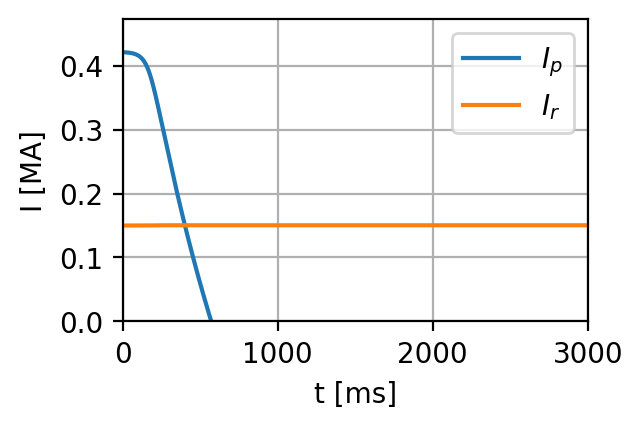

In [271]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)
plt.plot(t*1e3,Ip/1e6,label='$I_p$')
plt.plot(t*1e3,Ir/1e6,label='$I_r$')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.ylim(ymin=0)
plt.xlim([0,solver.tmax*1e3])

plt.legend()


## Show detailed results

/var/folders/yx/1xzcdppn0xxd5w6bf_xnbgrw0000gn/T/ipykernel_67588/1648650628.py:65: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  axs[3, 1].set_yscale('log')


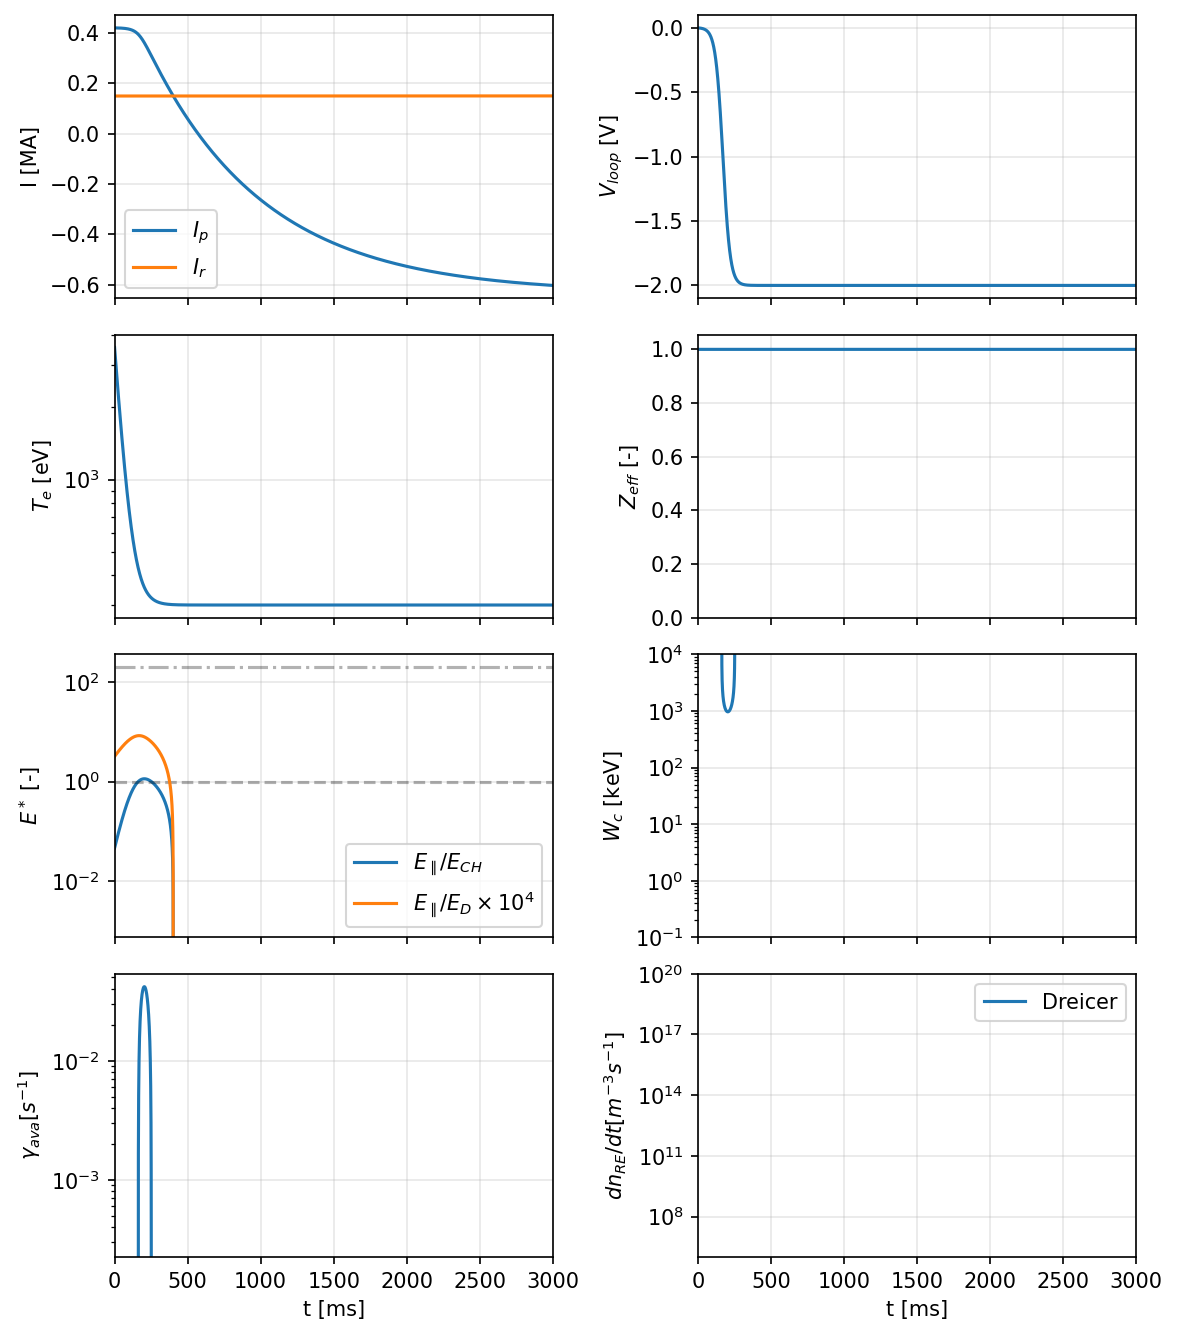

In [272]:
# Use the dictionary stored inside the solver object
d = solver.diag

# Expanded to 4 rows and 2 columns to fit the new subplots nicely
fig, axs = plt.subplots(4, 2, sharex=True, figsize=(8, 9), dpi=150)

# ==========================================
# ROW 0: Currents & Loop Voltage
# ==========================================
# [0,0] Currents - Compare Plasma vs Runaway
axs[0, 0].plot(d['t'] * 1e3, Ip / 1e6, label='$I_p$')
axs[0, 0].plot(d['t'] * 1e3, Ir / 1e6, label='$I_r$')
axs[0, 0].set_ylabel('I [MA]')
axs[0, 0].legend()

# [0,1] Loop Voltage (New Subplot)
axs[0, 1].plot(d['t'] * 1e3, d['Vloop'])
axs[0, 1].set_ylabel('$V_{loop}$ [V]')

# ==========================================
# ROW 1: Plasma Parameters (Te & Zeff)
# ==========================================
# [1,0] Electron Temperature
axs[1, 0].plot(d['t'] * 1e3, d['Te'])
axs[1, 0].set_ylabel('$T_e$ [eV]')
axs[1, 0].set_yscale('log')

# [1,1] Effective Charge Zeff (New Subplot)
axs[1, 1].plot(d['t'] * 1e3, d['Zeff'])
axs[1, 1].set_ylabel('$Z_{eff}$ [-]')
axs[1, 1].set_ylim(ymin=0)

# ==========================================
# ROW 2: Fields & Energy Scales
# ==========================================
# [2,0] Normalized Electric Fields
axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
axs[2, 0].axhline(1, color='k', linestyle='--', alpha=0.3)
axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e4, label='$E_\parallel/E_D \\times 10^4$')
axs[2, 0].axhline(2e-2 * 1e4, color='k', linestyle='-.', alpha=0.3)
axs[2, 0].set_ylabel('$E^*$ [-]')
axs[2, 0].set_yscale('log')
axs[2, 0].legend()

# [2,1] Critical Energy
from RE import getCriticalRunawayEnergy
import scipy.constants as const
Wc = getCriticalRunawayEnergy(d['E_star']) / const.eV
axs[2, 1].plot(d['t'] * 1e3, Wc / 1e3)
axs[2, 1].set_ylabel('$W_c$ [keV]')
axs[2, 1].set_yscale('log')
axs[2, 1].set_ylim([1e-1, 1e4])

# ==========================================
# ROW 3: RE Rates & Kinetics
# ==========================================
# [3,0] Avalanche Growth Rate
axs[3, 0].plot(d['t'] * 1e3, d['gamma_ava'])
axs[3, 0].set_ylabel('$\gamma_{ava} [s^{-1}]$')
axs[3, 0].set_yscale('log')

# [3,1] Primary Source Rates (Dreicer)
axs[3, 1].plot(d['t'] * 1e3, d['SD'], label='Dreicer')
axs[3, 1].set_ylabel('$dn_{RE}/dt [m^{-3}s^{-1}]$')
axs[3, 1].set_yscale('log')
axs[3, 1].set_ylim([1e6, 1e20])
axs[3, 1].legend()

# ==========================================
# Global Formatting
# ==========================================
for ax in axs.flat:
    ax.grid(True, alpha=0.3)
    ax.set_xlim([0, d['t'].max() * 1e3])
    
# Only label X-axes for the bottom-most row since sharex=True is enabled
axs[3, 0].set_xlabel('t [ms]')
axs[3, 1].set_xlabel('t [ms]')

plt.tight_layout()
plt.show()

In [273]:
solver.display()


 Constants:
Major radius R0 [m] = 2.535
Minor radius a [m] = 0.524
Elongation k [-] = 1.328
ni [per cubic m] = 2.5e+19
Inductance L [Henry] = 2.04e-06
Btor [Tesla] = 12.2

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 4.21e+05
Init. RE Current Ir0 [A] = 1.5e+05
Init. Temp. T0 [eV] = 3.55e+03
Final Temp. Tf [eV] = 300
Temp. decay time t0 [s] = 0.05
Init. Vloop V0 [V] = 0
Final Vloop Vf [V] = 0

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-10
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 1


# With non-zero driving Loop Voltage

In [274]:

# Loop Voltage
solver.V0 = 0.1
solver.Vf = 4.4

# Temperature
solver.T0 = 3e3
solver.Tf = 300
solver.t0 = 16e-3
solver.tstart = 50e-3


# Impurity
solver.Z_imp = 74 # impurity atomic no.
solver.A_imp = 184 # impurity weight
solver.n_imp = 0.5e-3 * solver.ni

# RE
solver.Ir0 = 1e3

solver.display()


 Constants:
Major radius R0 [m] = 2.535
Minor radius a [m] = 0.524
Elongation k [-] = 1.328
ni [per cubic m] = 2.5e+19
Inductance L [Henry] = 2.04e-06
Btor [Tesla] = 12.2

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 4.21e+05
Init. RE Current Ir0 [A] = 1e+03
Init. Temp. T0 [eV] = 3e+03
Final Temp. Tf [eV] = 300
Temp. decay time t0 [s] = 0.016
Init. Vloop V0 [V] = 0.1
Final Vloop Vf [V] = 4.4

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1.25e+16
Added Impurity Z, A [-] = 74, 184

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 1


In [275]:
# solve
solver.tmax = 600e-3 # end time [s]
solver.idiag = True # calculate detailed output
t, Ip, Ir, Wk = solver.solve()

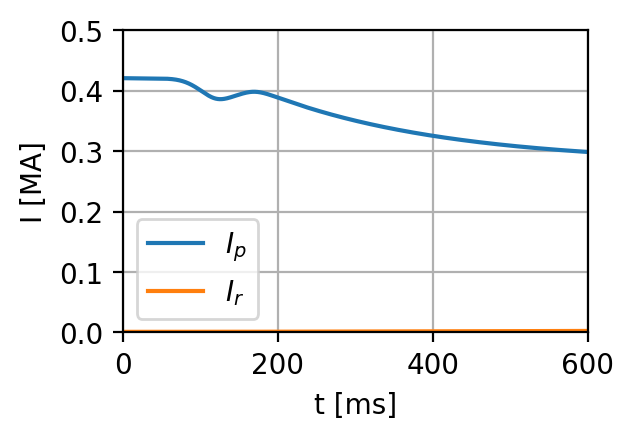

In [276]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)
plt.plot(t*1e3,Ip/1e6,label='$I_p$')
plt.plot(t*1e3,Ir/1e6,label='$I_r$')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.ylim([0,0.5])
plt.xlim([0,solver.tmax*1e3])

plt.legend()


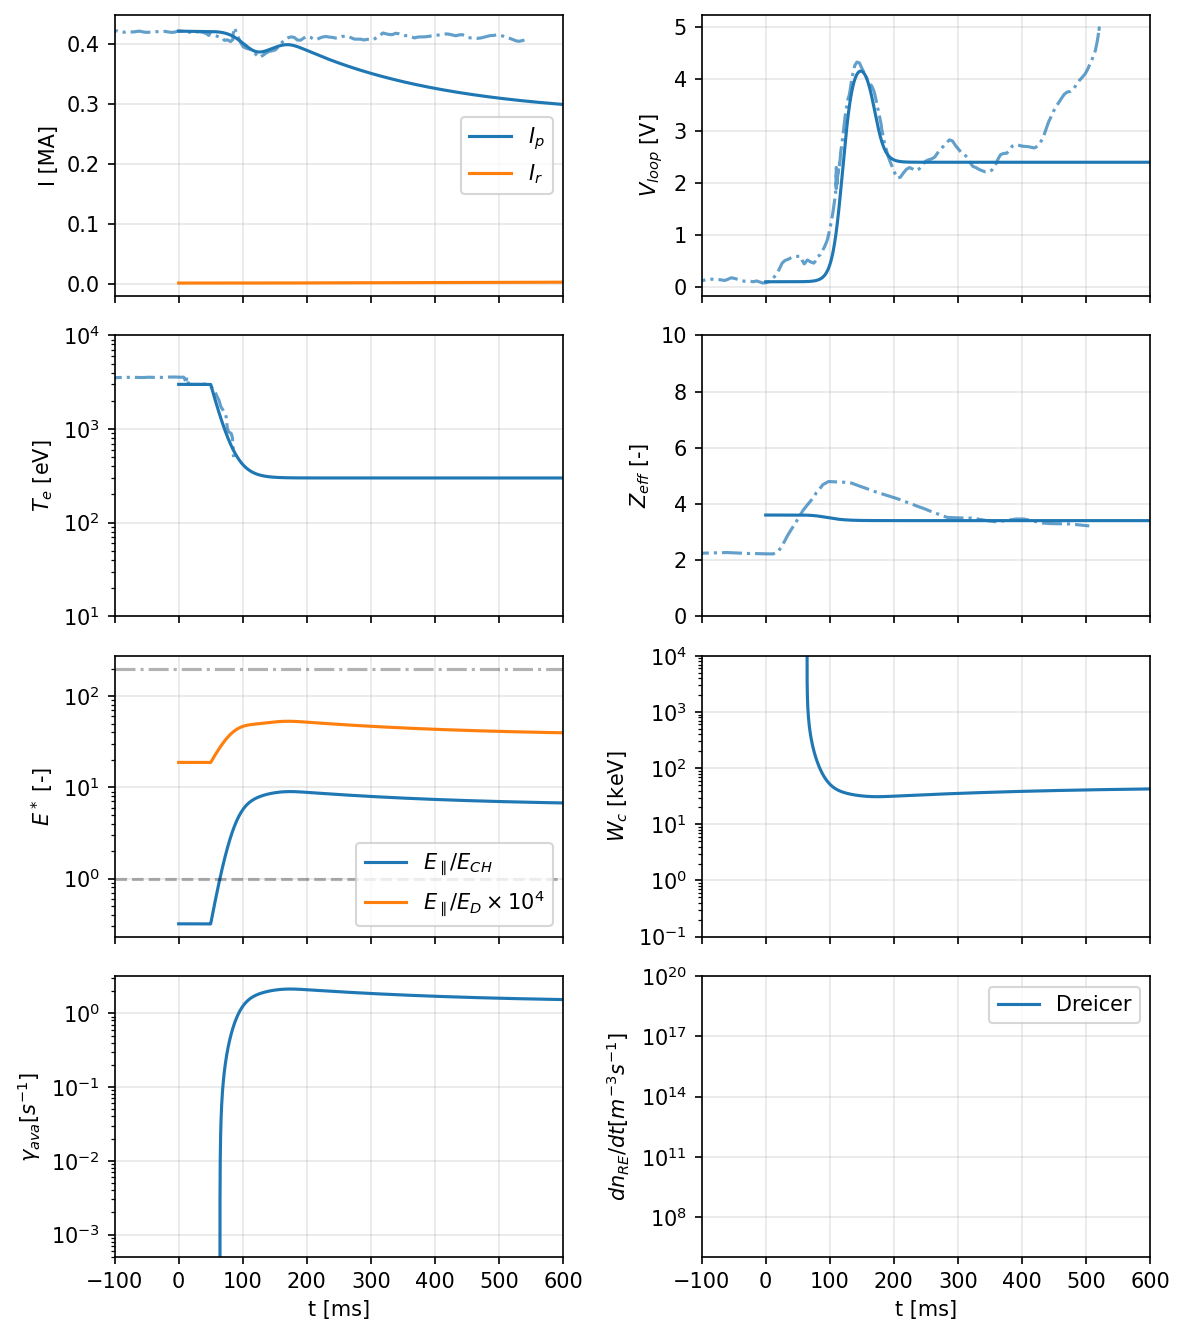

In [277]:
# Use the dictionary stored inside the solver object
d = solver.diag

# Expanded to 4 rows and 2 columns to fit the new subplots nicely
fig, axs = plt.subplots(4, 2, sharex=True, figsize=(8, 9), dpi=150)

# ==========================================
# ROW 0: Currents & Loop Voltage
# ==========================================
# [0,0] Currents - Compare Plasma vs Runaway
axs[0, 0].plot(d['t'] * 1e3, Ip / 1e6, label='$I_p$')
axs[0, 0].plot(d['t'] * 1e3, Ir / 1e6, label='$I_r$')
axs[0, 0].set_ylabel('I [MA]')
axs[0, 0].legend()

# [0,1] Loop Voltage (New Subplot)
axs[0, 1].plot(d['t'] * 1e3, d['Vloop'])
axs[0, 1].set_ylabel('$V_{loop}$ [V]')

# ==========================================
# ROW 1: Plasma Parameters (Te & Zeff)
# ==========================================
# [1,0] Electron Temperature
axs[1, 0].plot(d['t'] * 1e3, d['Te'])
axs[1, 0].set_ylabel('$T_e$ [eV]')
axs[1, 0].set_ylim([10,1e4])
axs[1, 0].set_yscale('log')

# [1,1] Effective Charge Zeff (New Subplot)
axs[1, 1].plot(d['t'] * 1e3, d['Zeff'])
axs[1, 1].set_ylabel('$Z_{eff}$ [-]')
axs[1, 1].set_ylim([0,10])

# ==========================================
# ROW 2: Fields & Energy Scales
# ==========================================
# [2,0] Normalized Electric Fields
axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
axs[2, 0].axhline(1, color='k', linestyle='--', alpha=0.3)
axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e4, label='$E_\parallel/E_D \\times 10^4$')
axs[2, 0].axhline(2e-2 * 1e4, color='k', linestyle='-.', alpha=0.3)
axs[2, 0].set_ylabel('$E^*$ [-]')
axs[2, 0].set_yscale('log')
axs[2, 0].legend()

# [2,1] Critical Energy
from RE import getCriticalRunawayEnergy
import scipy.constants as const
Wc = getCriticalRunawayEnergy(d['E_star']) / const.eV
axs[2, 1].plot(d['t'] * 1e3, Wc / 1e3)
axs[2, 1].set_ylabel('$W_c$ [keV]')
axs[2, 1].set_yscale('log')
axs[2, 1].set_ylim([1e-1, 1e4])

# ==========================================
# ROW 3: RE Rates & Kinetics
# ==========================================
# [3,0] Avalanche Growth Rate
axs[3, 0].plot(d['t'] * 1e3, d['gamma_ava'])
axs[3, 0].set_ylabel('$\gamma_{ava} [s^{-1}]$')
axs[3, 0].set_yscale('log')

# [3,1] Primary Source Rates (Dreicer)
axs[3, 1].plot(d['t'] * 1e3, d['SD'], label='Dreicer')
axs[3, 1].set_ylabel('$dn_{RE}/dt [m^{-3}s^{-1}]$')
axs[3, 1].set_yscale('log')
axs[3, 1].set_ylim([1e6, 1e20])
axs[3, 1].legend()

# ==========================================
# Global Formatting
# ==========================================
for ax in axs.flat:
    ax.grid(True, alpha=0.3)
    ax.set_xlim([-100, d['t'].max() * 1e3])
    
# Only label X-axes for the bottom-most row since sharex=True is enabled
axs[3, 0].set_xlabel('t [ms]')
axs[3, 1].set_xlabel('t [ms]')


###############################
### Compare with Expeirment ###
###############################

tshift = 120e-3

ip = np.loadtxt('./data/WEST_data/WEST_Ip_x0p1MA.csv',delimiter=',')
axs[0, 0].plot((ip[:,0]-ip[0,0]-tshift)*1e3,ip[:,1]*0.1,'-.',color='tab:blue',alpha=0.7)

te = np.loadtxt('./data/WEST_data/WEST_Te_keV.csv',delimiter=',')
axs[1, 0].plot((te[:,0]-te[0,0]-tshift)*1e3,te[:,1]*1e3,'-.',color='tab:blue',alpha=0.7)

vext = np.loadtxt('./data/WEST_data/WEST_Vloop_V.csv',delimiter=',')
axs[0, 1].plot((vext[:,0]-vext[0,0]-tshift)*1e3,vext[:,1],'-.',color='tab:blue',alpha=0.7)

zeff = np.loadtxt('./data/WEST_data/WEST_Zeff.csv',delimiter=',')
axs[1, 1].plot((zeff[:,0]-zeff[0,0]-tshift)*1e3,zeff[:,1],'-.',color='tab:blue',alpha=0.7)

plt.tight_layout()
plt.show()

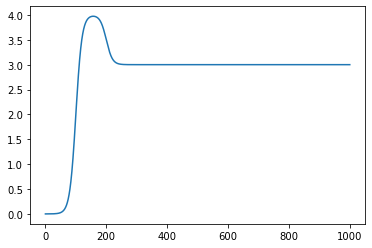

In [213]:
out = (solver.V0 +
    (solver.Vf-solver.V0) * (1 + np.tanh((d['t']-100e-3)/solver.t0))/2 
    - 1 * (1+np.tanh((d['t']-200e-3)/solver.t0))/2)
plt.plot(d['t']*1e3,out)

# Temperature scan

solver.Tf =  300
solver.Tf =  100
solver.Tf =  50
solver.Tf =  10
solver.Tf =  5


(0.0, 3150.0)

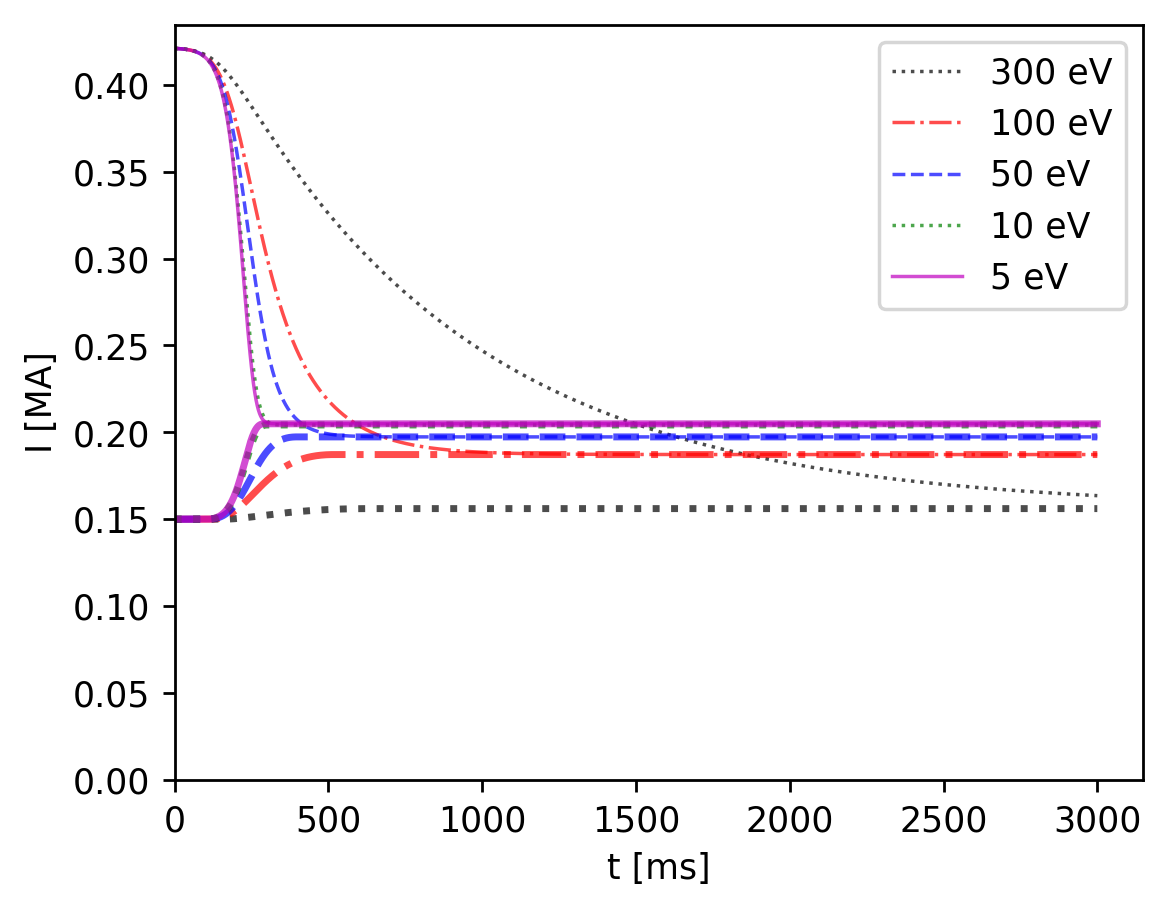

In [65]:
Tfvals = np.array([300,100,50,10,5])
out = np.zeros_like(Tfvals)
solver.idiag=False

colors = ['k','r','b','g','m']
lines = [':','-.','--',':','-']

fig, axs = plt.subplots(1,1,figsize=(5,4),dpi=250)

for ii in range(Tfvals.shape[0]):
    solver.Tf = Tfvals[ii]
    print('solver.Tf = ',solver.Tf)
    t, Ip, Ir, Wk = solver.solve()
    out[ii] = Ir[-1]
    plt.plot(t*1e3,Ip/1e6,color=colors[ii],linestyle=lines[ii],alpha=0.7,linewidth=1,label= str(Tfvals[ii]) + ' eV')
    plt.plot(t*1e3,Ir/1e6,color=colors[ii],linestyle=lines[ii],alpha=0.7,linewidth=2)
    

plt.legend()    
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.ylim(ymin=0)
plt.xlim(xmin=0)
    
    

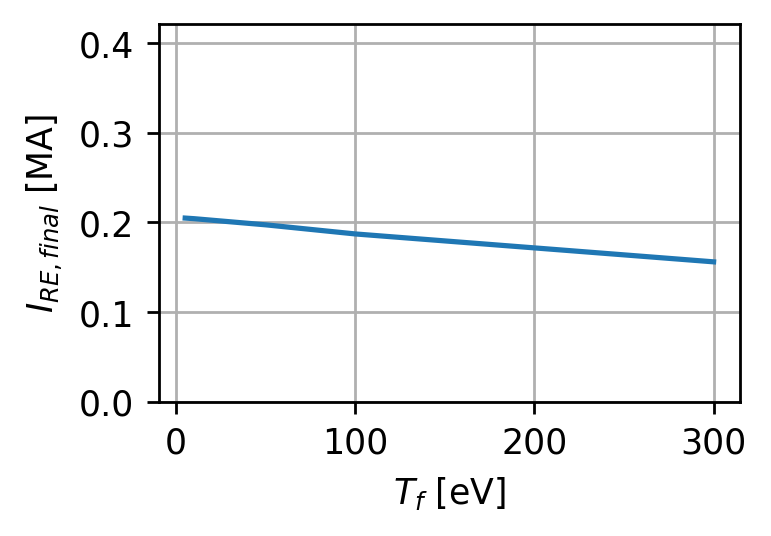

In [36]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=250)

axs.plot(Tfvals,out/1e6)
axs.set_xlabel('$T_f$ [eV]')
axs.set_ylabel('$I_{RE,final}$ [MA]')
axs.set_ylim([0,solver.I0/1e6])
axs.grid()


In [37]:
solver.display()


 Constants:
Major radius R0 [m] = 2.535
Minor radius a [m] = 0.524
Elongation k [-] = 1.328
ni [per cubic m] = 2.5e+19
Inductance L [Henry] = 2.04e-06
Btor [Tesla] = 12.2

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 4.21e+05
Init. RE Current Ir0 [A] = 1.5e+05
Init. Temp. T0 [eV] = 3.55e+03
Final Temp. Tf [eV] = 5
Temp. decay time t0 [s] = 0.05

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 1


# Impurity Scan

solver.n_imp =  1e+16
solver.n_imp =  1e+17
solver.n_imp =  1e+18
solver.n_imp =  1e+19
solver.n_imp =  1e+20


(0.0, 3150.0)

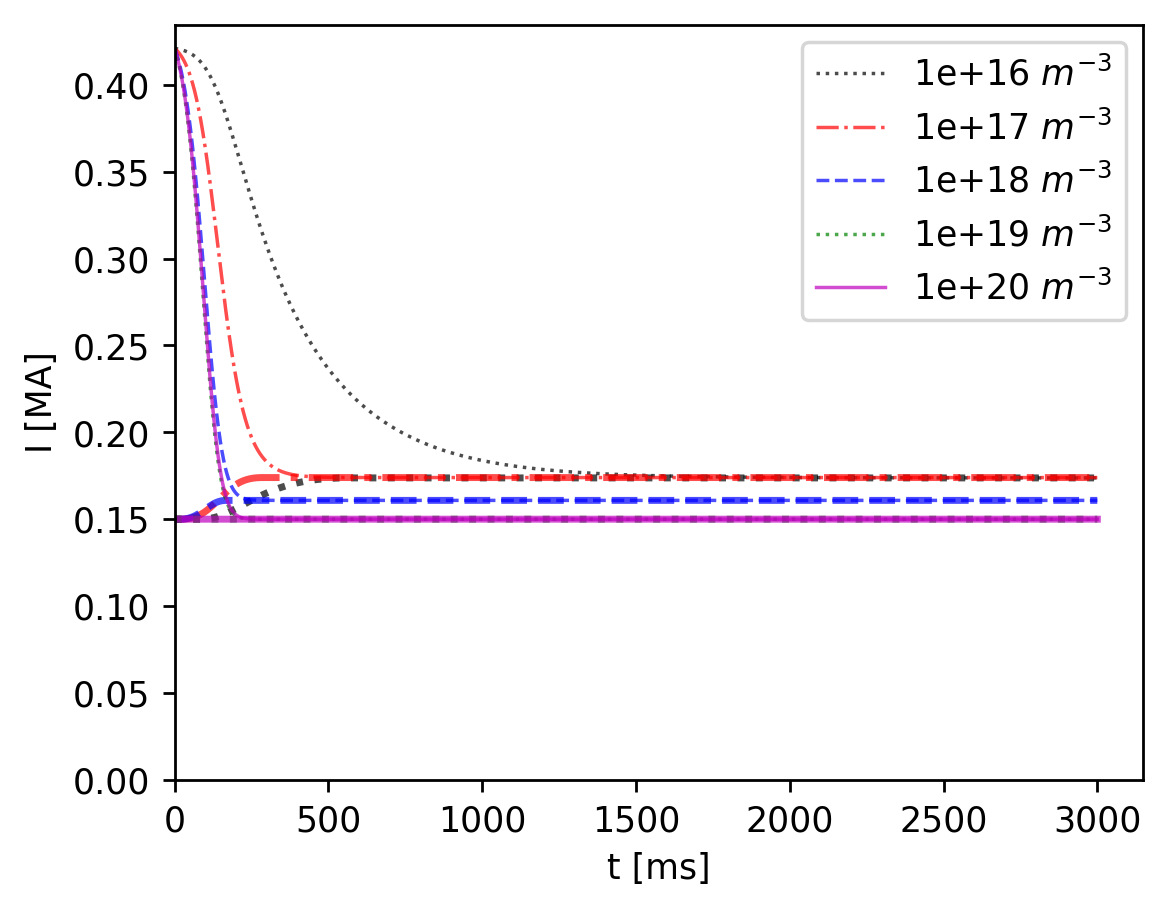

In [103]:
nimp_vals = np.array([1e16,1e17,1e18,1e19,1e20])
out = np.zeros_like(nimp_vals)
solver.idiag=False
solver.Tf = 300

solver.Z_imp = 74 # impurity atomic no.
solver.A_imp = 184 # impurity weight

colors = ['k','r','b','g','m']
lines = [':','-.','--',':','-']

fig, axs = plt.subplots(1,1,figsize=(5,4),dpi=250)

for ii in range(nimp_vals.shape[0]):
    solver.n_imp = nimp_vals[ii] # impurity density
    print('solver.n_imp = ',solver.n_imp)
    t, Ip, Ir, Wk = solver.solve()
    out[ii] = Ir[-1]
    plt.plot(t*1e3,Ip/1e6,color=colors[ii],linestyle=lines[ii],alpha=0.7,linewidth=1,label= str(nimp_vals[ii]) + ' $m^{-3}$')
    plt.plot(t*1e3,Ir/1e6,color=colors[ii],linestyle=lines[ii],alpha=0.7,linewidth=2)
    

plt.legend()    
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.ylim(ymin=0)
plt.xlim(xmin=0)
    
    

In [104]:
solver.idiag=True
solver.n_imp = 1e17
solver.display()
t, Ip, Ir, Wk = solver.solve()


 Constants:
Major radius R0 [m] = 2.535
Minor radius a [m] = 0.524
Elongation k [-] = 1.328
ni [per cubic m] = 2.5e+19
Inductance L [Henry] = 2.04e-06
Btor [Tesla] = 12.2

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 4.21e+05
Init. RE Current Ir0 [A] = 1.5e+05
Init. Temp. T0 [eV] = 3.55e+03
Final Temp. Tf [eV] = 300
Temp. decay time t0 [s] = 0.05

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e+17
Added Impurity Z, A [-] = 74, 184

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 1


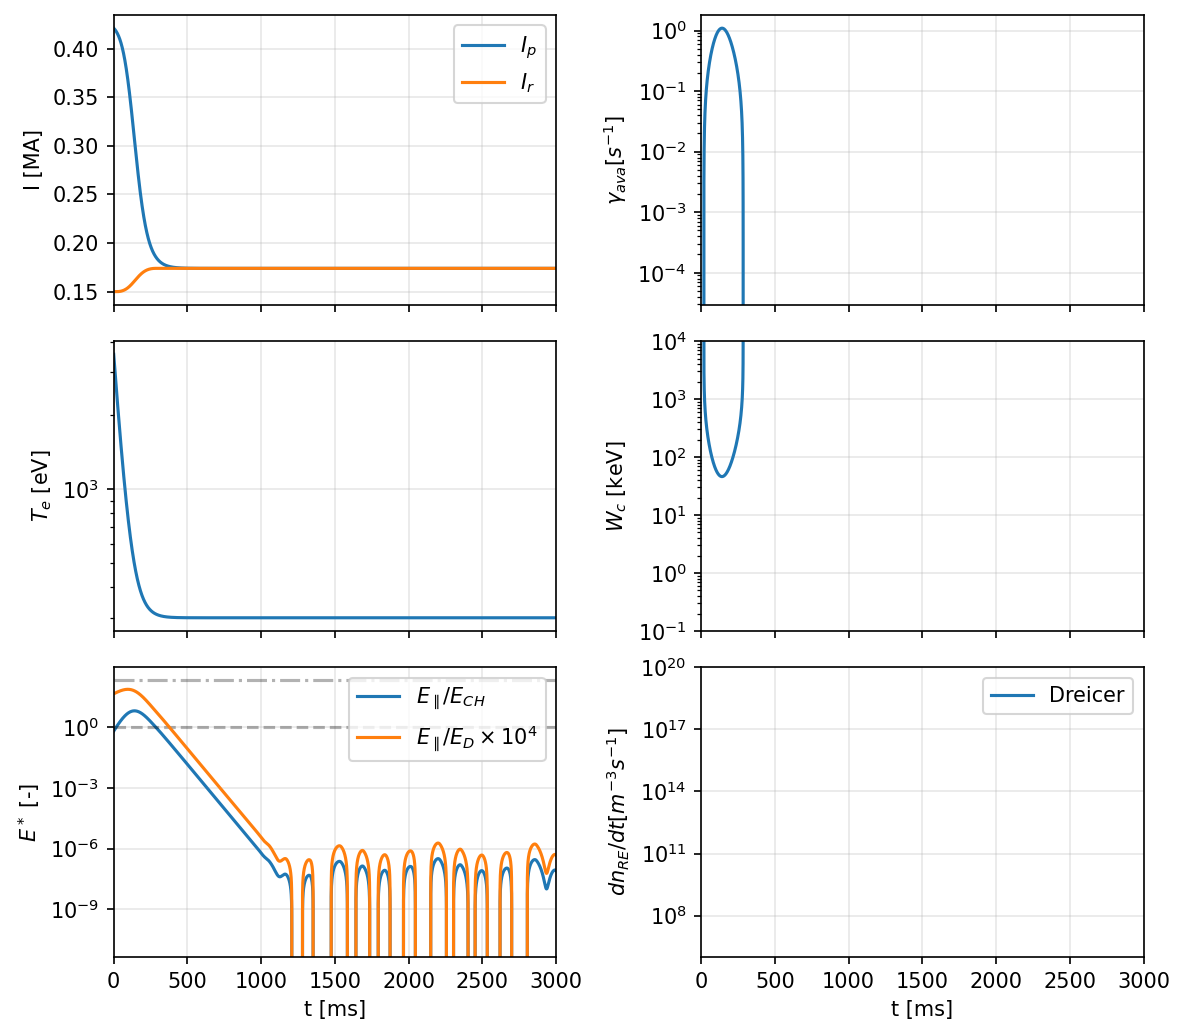

In [105]:
# Use the dictionary stored inside the solver object
d = solver.diag

fig, axs = plt.subplots(3, 2, sharex=True, figsize=(8, 7), dpi=150)

# [0,0] Currents - Compare Plasma vs Runaway
axs[0, 0].plot(d['t'] * 1e3, Ip / 1e6, label='$I_p$')
axs[0, 0].plot(d['t'] * 1e3, Ir / 1e6, label='$I_r$')
axs[0, 0].set_ylabel('I [MA]')
axs[0, 0].legend()

# [1,0] Electron Temperature
axs[1, 0].plot(d['t'] * 1e3, d['Te'])
axs[1, 0].set_ylabel('$T_e$ [eV]')
axs[1, 0].set_yscale('log')

# [2,0] Normalized Electric Fields
axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
axs[2, 0].axhline(1, color='k', linestyle='--', alpha=0.3)
axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e4, label='$E_\parallel/E_D \\times 10^4$')
axs[2, 0].axhline(2e-2*1e4, color='k', linestyle='-.', alpha=0.3)
axs[2, 0].set_ylabel('$E^*$ [-]')
axs[2, 0].set_yscale('log')
axs[2, 0].legend()

# [0,1] Avalanche Growth Rate
axs[0, 1].plot(d['t'] * 1e3, d['gamma_ava'])
axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')
axs[0, 1].set_yscale('log')

# [1,1] Critical Energy (Recalculated for visualization)
# Since Wc isn't in your diag dict yet, we use the solver's imported function
from RE import getCriticalRunawayEnergy
import scipy.constants as const
Wc = getCriticalRunawayEnergy(d['E_star']) / const.eV
axs[1, 1].plot(d['t'] * 1e3, Wc / 1e3)
axs[1, 1].set_ylabel('$W_c$ [keV]')
axs[1, 1].set_yscale('log')
axs[1, 1].set_ylim([1e-1, 1e4])

# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['SD'], label='Dreicer')
# axs[2, 1].plot(d['t'] * 1e3, d['ST'], label='Tritium')
# axs[2, 1].plot(d['t'] * 1e3, d['SC'], label='Compton')
axs[2, 1].set_ylabel('$dn_{RE}/dt [m^{-3}s^{-1}]$')
axs[2, 1].set_yscale('log')
axs[2, 1].set_ylim([1e6, 1e20])
axs[2, 1].legend()

# Global formatting
for ax in axs.flat:
    ax.grid(True, alpha=0.3)
    ax.set_xlim([0, d['t'].max() * 1e3])

axs[2, 0].set_xlabel('t [ms]')
axs[2, 1].set_xlabel('t [ms]')
plt.tight_layout()
plt.show()

Text(0, 0.5, 'Zeff [-]')

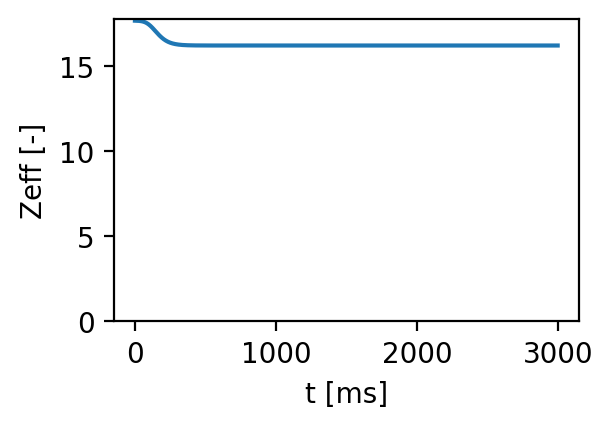

In [106]:

fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200)
plt.plot(d['t']*1e3,d['Zeff'])
plt.ylim(ymin=0)
plt.xlabel('t [ms]')
plt.ylabel('Zeff [-]')

# Hot-tail generation

In [111]:
def temperature(t, T0, Tf, t0):
    """
    Parameters:
    t: Time (s)
    T0: initial temp (eV)
    Tfinal: final temp (eV)
    t0: initial time (s)
    """
    return Tf + (T0 - Tf) * np.exp(-t / t0)


# Constants
T0 = solver.T0    # eV
Tf = solver.Tf # eV
t0 = solver.t0/100    # s
n0 = solver.ni # m^-3
E0 = solver.diag['Epar'][0] # V/m

t = np.linspace(0,t0*10,1000)
nht = np.zeros_like(t)
nht_rate = np.zeros_like(t)
dt = np.diff(t)[0]

for ii in range(1,t.shape[0]):
    T = temperature(t[ii], T0, Tf, t0) # eV
    # Rate
    nht_rate[ii], nht[ii] = RE.get_HT_rate(ne=n0,
                                           T=T,
                                           t=t[ii],
                                           T0=T0,
                                           E0=E0,
                                           nht=nht[ii-1],
                                           dt=dt)

Iht = 27.8 kA


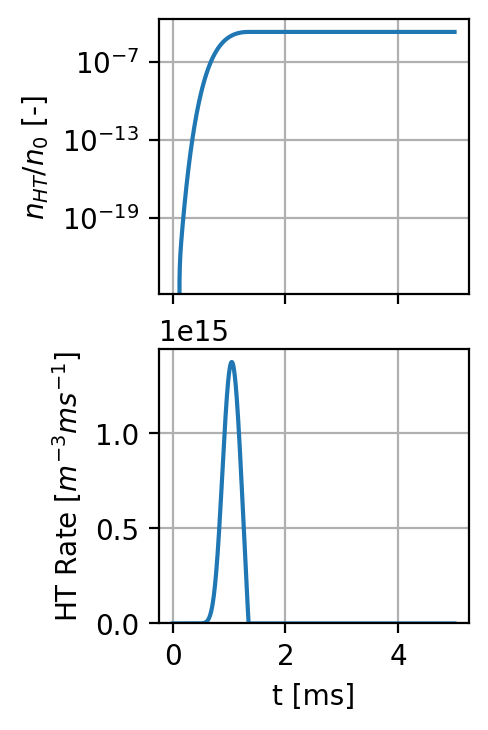

In [112]:
# Plot
fig, axs = plt.subplots(2,1,sharex=True,figsize=(2,4),dpi=200)
axs[0].plot(t*1e3,nht/n0,'-')
axs[0].set_ylabel('$n_{HT}/n_0$ [-]')
axs[0].set_yscale('log')
# axs[0].set_ylim([1e-8,1e0])
axs[0].grid()

axs[1].plot(t*1e3,nht_rate / 1e3,'-')
axs[1].set_ylabel('HT Rate [$m^{-3} ms^{-1}$]')
axs[1].set_ylim(ymin=0)
axs[1].grid()
axs[-1].set_xlabel('t [ms]')
    
    
# HT Current
Iht = nht[-1] * const.c * const.e * np.pi * 0.6**2
print('Iht = %1.3g kA'%(Iht/1e3))
